# NSL-KDD: does the log transform help the deep models?

The same experiment that was run on CICIDS2017, where a signed log transform of the input features lifted the deep models a lot (CNN macro F1 0.782 to 0.912, LSTM 0.854 to 0.927), because that dataset's features are extremely heavy-tailed and `StandardScaler` squashes most values near zero while a few outliers become huge. NSL-KDD also has heavy-tailed features (`src_bytes`, `dst_bytes`, `duration` and the count features), so this notebook tests whether the same trick helps here. It is exploratory and separate from the main grid.

## What this notebook does

1. **Rebuilds the NSL-KDD data** from `KDDTrain+.csv` and `KDDTest+.csv` with exactly the preprocessing of `NSLKDD_Preprocessing.ipynb` (same attack-to-class mapping, same one-hot encoding), with one change: before standard scaling, every feature goes through the **signed log transform** `sign(x) * log(1 + |x|)`. One-hot columns are unaffected in effect (a 0/1 column stays a two-valued column after scaling).
2. **Trains two models on the transformed data**, each with the baseline recipe (no search): the **CNN** and the **LSTM (features, 64 units)**, with the same settings as their baseline runs.
3. **Compares them** with the existing baseline and optimised runs and the Decision Tree and Random Forest, from the JSON files in `results/`. Trees are not affected by the transform (they only use the order of values), so their numbers from the main grid are the right comparison.

By default there is **no class weighting** (`ALPHA = 0`), so the only change from the baseline runs is the transform. If you want the "log transform + weighting" variant afterwards, set `ALPHA = 0.8` (the value fixed for the NSL-KDD optimised runs) and run again; it writes a separate file. Do not pick `ALPHA` by looking at test scores.

## Before running

- Put `KDDTrain+.csv` and `KDDTest+.csv` (the versions with attack names) where the first data cell points (`train_path`, `test_path`), the same as for `NSLKDD_Preprocessing.ipynb`.
- Keep `results/NSL-KDD_CNN.json`, `results/NSL-KDD_LSTM_features.json`, the two `..._optimised.json` files and the Decision Tree and Random Forest JSONs in place for the final comparison (it skips any that are missing). If `nslkdd.npz` is in the folder, the notebook also checks that the new split is identical to it.
- The NSL-KDD LSTM uses the **features** mode (the 118 features as 118 time steps), as in the baseline run. That mode is slow: the baseline took about 34 minutes on a CPU, and a GPU makes it far faster. The CNN is quick. Set `RUN_LSTM = False` to skip it.
- Each result is saved as soon as it finishes to `results/NSL-KDD_logtransform.json` (or `..._logtransform_alpha<value>.json` if `ALPHA` is above 0). Send me that file.

## How to report it

One run per model, settings fixed in advance. If the transform helps, say so; if not, say it was tried and did not help. Either is a fair result.

## Settings

In [3]:
import gc
import json
import os
import re
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, precision_recall_fscore_support, f1_score)

import keras
from keras import layers
from keras.callbacks import EarlyStopping
import tensorflow as tf
print("GPUs visible:", tf.config.list_physical_devices("GPU"))

SEED = 0
DATASET_NAME = "NSL-KDD"

RUN_CNN = True
RUN_LSTM = True

# 0 = no class weighting (the baseline recipe, so the transform is the only change).
# Above 0 = tempered class weights (1 = "balanced"), for the "log transform + weighting" variant.
ALPHA = 0.0

BATCH_SIZE = 256       # same as the baseline CNN and LSTM notebooks
EPOCHS = 50
PATIENCE = 5
BASELINE_NPZ = "nslkdd.npz"   # optional: if present, the new data is checked against it

GPUs visible: []


## 1. Rebuild the data (same steps as the preprocessing notebook)

The next cells are the preprocessing notebook's own cells (load the two files, map attacks to the five classes, drop columns, one-hot encode, align, label-encode), unchanged. Only the scaling differs.

In [4]:
import numpy as np
import pandas as pd
train_path = "KDDTrain+.csv"
test_path = "KDDTest+.csv"

columns = [
    'duration', 'protocol_type', 'service', 'flag', 'src_bytes', 'dst_bytes', 'land',
    'wrong_fragment', 'urgent', 'hot', 'num_failed_logins', 'logged_in', 'num_compromised',
    'root_shell', 'su_attempted', 'num_root', 'num_file_creations', 'num_shells',
    'num_access_files', 'num_outbound_cmds', 'is_host_login', 'is_guest_login', 'count',
    'srv_count', 'serror_rate', 'srv_serror_rate', 'rerror_rate', 'srv_rerror_rate',
    'same_srv_rate', 'diff_srv_rate', 'srv_diff_host_rate', 'dst_host_count',
    'dst_host_srv_count', 'dst_host_same_srv_rate', 'dst_host_diff_srv_rate',
    'dst_host_same_src_port_rate', 'dst_host_srv_diff_host_rate', 'dst_host_serror_rate',
    'dst_host_srv_serror_rate', 'dst_host_rerror_rate', 'dst_host_srv_rerror_rate',
    'attack', 'difficulty'
]

df_train = pd.read_csv(train_path, header=None, names=columns)
df_test = pd.read_csv(test_path, header=None, names=columns)

print("Train:", df_train.shape, "| Test:", df_test.shape)
df_train.head()

Train: (125973, 43) | Test: (22543, 43)


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,attack,difficulty
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal,20
1,0,udp,other,SF,146,0,0,0,0,0,...,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal,15
2,0,tcp,private,S0,0,0,0,0,0,0,...,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune,19
3,0,tcp,http,SF,232,8153,0,0,0,0,...,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal,21
4,0,tcp,http,SF,199,420,0,0,0,0,...,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal,21


In [5]:
attack_map = {'normal': 'Normal'}
for a in ['back', 'land', 'neptune', 'pod', 'smurf', 'teardrop', 'apache2', 'mailbomb', 'processtable', 'udpstorm']:
    attack_map[a] = 'DoS'
for a in ['ipsweep', 'nmap', 'portsweep', 'satan', 'mscan', 'saint']:
    attack_map[a] = 'Probe'
for a in ['ftp_write', 'guess_passwd', 'imap', 'multihop', 'phf', 'spy', 'warezclient', 'warezmaster',
          'named', 'sendmail', 'snmpgetattack', 'snmpguess', 'worm', 'xlock', 'xsnoop']:
    attack_map[a] = 'R2L'
for a in ['buffer_overflow', 'loadmodule', 'perl', 'rootkit', 'ps', 'sqlattack', 'xterm', 'httptunnel']:
    attack_map[a] = 'U2R'

df_train['category'] = df_train['attack'].map(attack_map)
df_test['category'] = df_test['attack'].map(attack_map)

# Any attack name missing from the map would show up here as NaN
assert df_train['category'].notna().all(), df_train.loc[df_train['category'].isna(), 'attack'].unique()
assert df_test['category'].notna().all(), df_test.loc[df_test['category'].isna(), 'attack'].unique()

In [6]:
drop_cols = ['attack', 'difficulty', 'category', 'num_outbound_cmds']

X_train_raw = df_train.drop(columns=drop_cols)
y_train_raw = df_train['category']
X_test_raw = df_test.drop(columns=drop_cols)
y_test_raw = df_test['category']

categorical_cols = ['protocol_type', 'service', 'flag']

X_train_encoded = pd.get_dummies(X_train_raw, columns=categorical_cols, drop_first=True)
X_test_encoded = pd.get_dummies(X_test_raw, columns=categorical_cols, drop_first=True)

# Align columns: test may be missing categories seen in train
X_train_encoded, X_test_encoded = X_train_encoded.align(X_test_encoded, join='left', axis=1, fill_value=0)

print("Feature count after encoding:", X_train_encoded.shape[1])

Feature count after encoding: 118


In [7]:
label_encoder = LabelEncoder()
y_train_encoded = label_encoder.fit_transform(y_train_raw)
y_test_encoded = label_encoder.transform(y_test_raw)

class_names = label_encoder.classes_
num_classes = len(class_names)
print("Classes:", class_names)

Classes: ['DoS' 'Normal' 'Probe' 'R2L' 'U2R']


In [8]:
X_train = X_train_encoded.to_numpy(dtype="float64")
X_test = X_test_encoded.to_numpy(dtype="float64")
y_train, y_test = y_train_encoded, y_test_encoded
class_names = [str(c) for c in class_names]
n_classes = len(class_names)

## 2. Signed log transform, then standard scaling

Applied to every row of the training and test sets alike, so it uses nothing from the test set. The scaler is fitted on the (transformed) training set only.

In [9]:
def signed_log(a):
    return np.sign(a) * np.log1p(np.abs(a))

X_train = signed_log(X_train.astype("float64"))
X_test = signed_log(X_test.astype("float64"))

scaler = StandardScaler()                      # fitted on the (transformed) training set only
X_train = scaler.fit_transform(X_train).astype("float32")
X_test = scaler.transform(X_test).astype("float32")
print("Largest absolute scaled value in train:", float(np.abs(X_train).max()))
print("Train:", X_train.shape, "| Test:", X_test.shape)
print(dict(zip(class_names, np.bincount(y_train, minlength=n_classes).tolist())))

# Check that this is the same data as the baseline runs used
if os.path.exists(BASELINE_NPZ):
    ref = np.load(BASELINE_NPZ)
    same = np.array_equal(ref["y_train"], y_train) and np.array_equal(ref["y_test"], y_test) and ref["X_train"].shape == X_train.shape
    print("Same rows, labels and feature count as", BASELINE_NPZ, ":", same)
    assert same, "The data differs from the one the baselines used. Check the file paths."
    del ref

Largest absolute scaled value in train: 354.92535400390625
Train: (125973, 118) | Test: (22543, 118)
{'DoS': 45927, 'Normal': 67343, 'Probe': 11656, 'R2L': 995, 'U2R': 52}
Same rows, labels and feature count as nslkdd.npz : True


In [10]:
def evaluate(model_name, config, y_true, y_pred, class_names):
    """Print the metrics, classification report and confusion matrix; return the numbers."""
    labels = np.arange(len(class_names))
    acc = accuracy_score(y_true, y_pred)
    macro_p, macro_r, macro_f1, _ = precision_recall_fscore_support(
        y_true, y_pred, labels=labels, average="macro", zero_division=0)
    weighted_f1 = f1_score(y_true, y_pred, labels=labels, average="weighted", zero_division=0)

    print(f"{model_name} ({DATASET_NAME}, {config})")
    print(f"Accuracy {acc:.4f} | Macro precision {macro_p:.3f} | Macro recall {macro_r:.3f} | "
          f"Macro F1 {macro_f1:.3f} | Weighted F1 {weighted_f1:.3f}\n")
    print(classification_report(y_true, y_pred, labels=labels, target_names=class_names,
                                zero_division=0))

    fig, ax = plt.subplots(figsize=(9, 7))
    ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred, labels=labels),
                           display_labels=class_names).plot(ax=ax, xticks_rotation=45,
                                                           cmap="Blues", colorbar=False)
    ax.set_title(f"{model_name} confusion matrix ({DATASET_NAME}, {config})")
    fig.tight_layout()
    plt.show()

    return {"accuracy": acc, "macro_precision": macro_p, "macro_recall": macro_r,
            "macro_f1": macro_f1, "weighted_f1": weighted_f1,
            "report": classification_report(y_true, y_pred, labels=labels,
                                            target_names=class_names, zero_division=0,
                                            output_dict=True)}

def plot_history(history, title):
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
    axes[0].plot(history.history["accuracy"], label="train")
    axes[0].plot(history.history["val_accuracy"], label="validation")
    axes[0].set_title(f"{title}: accuracy"); axes[0].set_xlabel("epoch"); axes[0].legend()
    axes[1].plot(history.history["loss"], label="train")
    axes[1].plot(history.history["val_loss"], label="validation")
    axes[1].set_title(f"{title}: loss"); axes[1].set_xlabel("epoch"); axes[1].legend()
    fig.tight_layout(); plt.show()

## 3. Models

The same sequence builder as the LSTM notebooks. With `window=None` it gives both models a (features, 1) input, the CNN's normal input and the LSTM's "features" mode, exactly as in the baseline runs. The validation split is the same stratified 10% (seed 0) as in the baselines.

In [11]:
class RowSequence(keras.utils.Sequence):
    """Yields (X, y[, sample_weight]) batches.
    window=None -> X is (batch, features, 1); window=W -> X is (batch, W, features).
    `indices` picks which rows are samples; a window always looks back at the real previous rows
    of X, even when only a subset of rows is used for training."""

    def __init__(self, X, y, indices, window=None, batch_size=256, shuffle=False,
                 weights=None, seed=SEED):
        super().__init__()
        self.X, self.y, self.weights = X, y, weights
        self.indices = np.array(indices)
        self.window, self.batch_size, self.shuffle = window, batch_size, shuffle
        self.rng = np.random.default_rng(seed)
        if shuffle:
            self.rng.shuffle(self.indices)

    def __len__(self):
        return int(np.ceil(len(self.indices) / self.batch_size))

    def __getitem__(self, i):
        idx = self.indices[i * self.batch_size:(i + 1) * self.batch_size]
        if self.window is None:
            xb = self.X[idx][:, :, None]
        else:
            offsets = np.arange(-self.window + 1, 1)
            xb = self.X[np.clip(idx[:, None] + offsets[None, :], 0, None)]
        yb = self.y[idx]
        if self.weights is None:
            return xb, yb
        return xb, yb, self.weights[yb]

    def on_epoch_end(self):
        if self.shuffle:
            self.rng.shuffle(self.indices)

In [12]:
n_features = X_train.shape[1]
window = None   # features mode: no neighbouring rows are used

tr_idx, val_idx = train_test_split(np.arange(len(X_train)), test_size=0.1,
                                   stratify=y_train, random_state=SEED)
test_all = np.arange(len(X_test))
results = {}
tag = "" if ALPHA == 0 else f"_alpha{ALPHA}"
OUT_FILE = f"results/{DATASET_NAME}_logtransform{tag}.json"

def class_weights_for(y, alpha):
    """Balanced weights raised to the power alpha, rescaled so the mean sample weight is 1."""
    counts = np.maximum(np.bincount(y, minlength=n_classes), 1)
    w = (len(y) / (n_classes * counts)) ** alpha
    return w / w[y].mean()

def build_cnn():
    return keras.Sequential([
        keras.Input(shape=(n_features, 1)),
        layers.Conv1D(64, kernel_size=3, activation="relu", padding="same"),
        layers.MaxPooling1D(pool_size=2),
        layers.Flatten(),
        layers.Dense(64, activation="relu"),
        layers.Dense(n_classes, activation="softmax"),
    ])

def build_lstm():
    return keras.Sequential([
        keras.Input(shape=(n_features, 1)),
        layers.LSTM(64),
        layers.Dense(n_classes, activation="softmax"),
    ])

def run(key, model_name, config, build, window):
    keras.utils.set_random_seed(SEED)
    w = None if ALPHA == 0 else class_weights_for(y_train[tr_idx], ALPHA)
    train_seq = RowSequence(X_train, y_train, tr_idx, window, BATCH_SIZE, shuffle=True, weights=w)
    val_seq = RowSequence(X_train, y_train, val_idx, window, 1024, weights=w)
    test_seq = RowSequence(X_test, y_test, test_all, window, 1024)
    model = build()
    model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    early_stop = EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True)
    start = time.perf_counter()
    history = model.fit(train_seq, validation_data=val_seq, epochs=EPOCHS,
                        callbacks=[early_stop], verbose=2)
    secs = time.perf_counter() - start
    print(f"Trained in {secs:.1f}s ({len(history.history['loss'])} epochs)")
    plot_history(history, config)
    y_pred = model.predict(test_seq, verbose=0).argmax(axis=1)
    result = evaluate(model_name, config, y_test, y_pred, class_names)
    result["train_seconds"] = secs
    result["epochs"] = len(history.history["loss"])
    result["alpha"] = ALPHA
    results[key] = result
    os.makedirs("results", exist_ok=True)
    json.dump(results, open(OUT_FILE, "w"), indent=1, default=float)
    del model
    keras.backend.clear_session()
    gc.collect()

## 4. CNN on log-transformed data

Epoch 1/50
443/443 - 3s - 6ms/step - accuracy: 0.9817 - loss: 0.0725 - val_accuracy: 0.9910 - val_loss: 0.0300
Epoch 2/50
443/443 - 2s - 4ms/step - accuracy: 0.9922 - loss: 0.0262 - val_accuracy: 0.9923 - val_loss: 0.0225
Epoch 3/50
443/443 - 2s - 4ms/step - accuracy: 0.9941 - loss: 0.0213 - val_accuracy: 0.9946 - val_loss: 0.0183
Epoch 4/50
443/443 - 2s - 5ms/step - accuracy: 0.9952 - loss: 0.0170 - val_accuracy: 0.9931 - val_loss: 0.0212
Epoch 5/50
443/443 - 2s - 5ms/step - accuracy: 0.9964 - loss: 0.0139 - val_accuracy: 0.9957 - val_loss: 0.0132
Epoch 6/50
443/443 - 2s - 4ms/step - accuracy: 0.9966 - loss: 0.0130 - val_accuracy: 0.9958 - val_loss: 0.0161
Epoch 7/50
443/443 - 2s - 4ms/step - accuracy: 0.9970 - loss: 0.0115 - val_accuracy: 0.9964 - val_loss: 0.0157
Epoch 8/50
443/443 - 2s - 4ms/step - accuracy: 0.9974 - loss: 0.0096 - val_accuracy: 0.9974 - val_loss: 0.0101
Epoch 9/50
443/443 - 2s - 4ms/step - accuracy: 0.9974 - loss: 0.0090 - val_accuracy: 0.9972 - val_loss: 0.0105
E

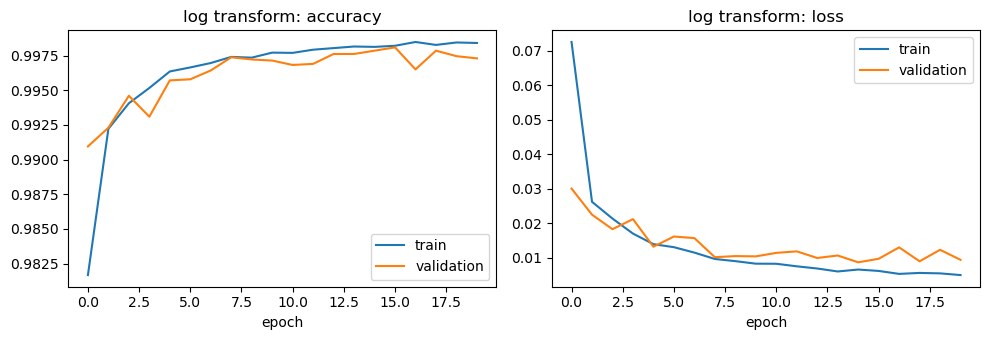

CNN (NSL-KDD, log transform)
Accuracy 0.7663 | Macro precision 0.652 | Macro recall 0.537 | Macro F1 0.546 | Weighted F1 0.738

              precision    recall  f1-score   support

         DoS       0.97      0.84      0.90      7458
      Normal       0.69      0.92      0.79      9710
       Probe       0.70      0.71      0.70      2421
         R2L       0.65      0.12      0.20      2754
         U2R       0.25      0.10      0.14       200

    accuracy                           0.77     22543
   macro avg       0.65      0.54      0.55     22543
weighted avg       0.77      0.77      0.74     22543



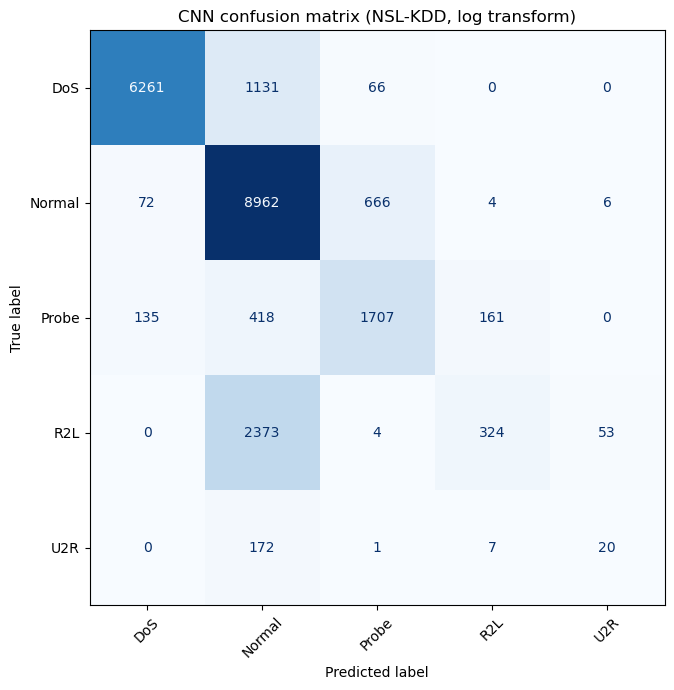

In [13]:
if RUN_CNN:
    run("cnn_log", "CNN", "log transform", build_cnn, window=None)
else:
    print("Skipped")

## 5. LSTM (features mode, 64 units) on log-transformed data

Epoch 1/50
443/443 - 31s - 69ms/step - accuracy: 0.8687 - loss: 0.4405 - val_accuracy: 0.9430 - val_loss: 0.2212
Epoch 2/50
443/443 - 29s - 66ms/step - accuracy: 0.9577 - loss: 0.1564 - val_accuracy: 0.9702 - val_loss: 0.1096
Epoch 3/50
443/443 - 33s - 74ms/step - accuracy: 0.9711 - loss: 0.1056 - val_accuracy: 0.9756 - val_loss: 0.0842
Epoch 4/50
443/443 - 35s - 78ms/step - accuracy: 0.9777 - loss: 0.0787 - val_accuracy: 0.9797 - val_loss: 0.0666
Epoch 5/50
443/443 - 35s - 78ms/step - accuracy: 0.9780 - loss: 0.0746 - val_accuracy: 0.9824 - val_loss: 0.0585
Epoch 6/50
443/443 - 34s - 77ms/step - accuracy: 0.9816 - loss: 0.0610 - val_accuracy: 0.9825 - val_loss: 0.0676
Epoch 7/50
443/443 - 34s - 77ms/step - accuracy: 0.9837 - loss: 0.0559 - val_accuracy: 0.9806 - val_loss: 0.0624
Epoch 8/50
443/443 - 35s - 79ms/step - accuracy: 0.9845 - loss: 0.0506 - val_accuracy: 0.9894 - val_loss: 0.0448
Epoch 9/50
443/443 - 34s - 76ms/step - accuracy: 0.9862 - loss: 0.0471 - val_accuracy: 0.9898 - 

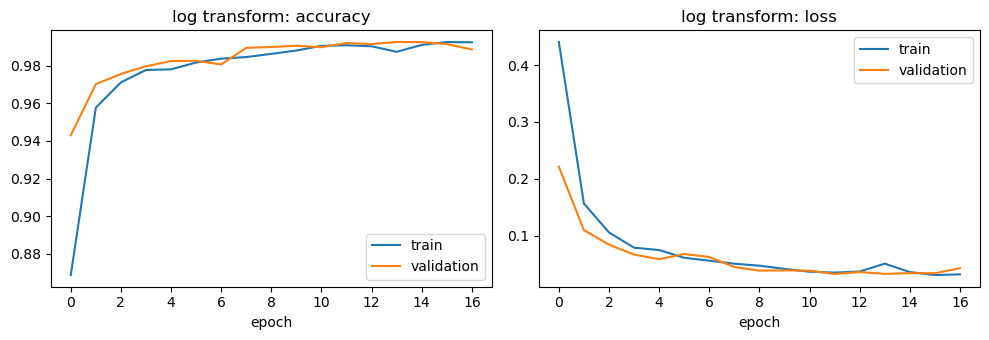

LSTM (features) (NSL-KDD, log transform)
Accuracy 0.7555 | Macro precision 0.632 | Macro recall 0.523 | Macro F1 0.509 | Weighted F1 0.722

              precision    recall  f1-score   support

         DoS       0.96      0.78      0.86      7458
      Normal       0.68      0.93      0.78      9710
       Probe       0.66      0.82      0.73      2421
         R2L       0.86      0.10      0.17      2754
         U2R       0.00      0.00      0.00       200

    accuracy                           0.76     22543
   macro avg       0.63      0.52      0.51     22543
weighted avg       0.79      0.76      0.72     22543



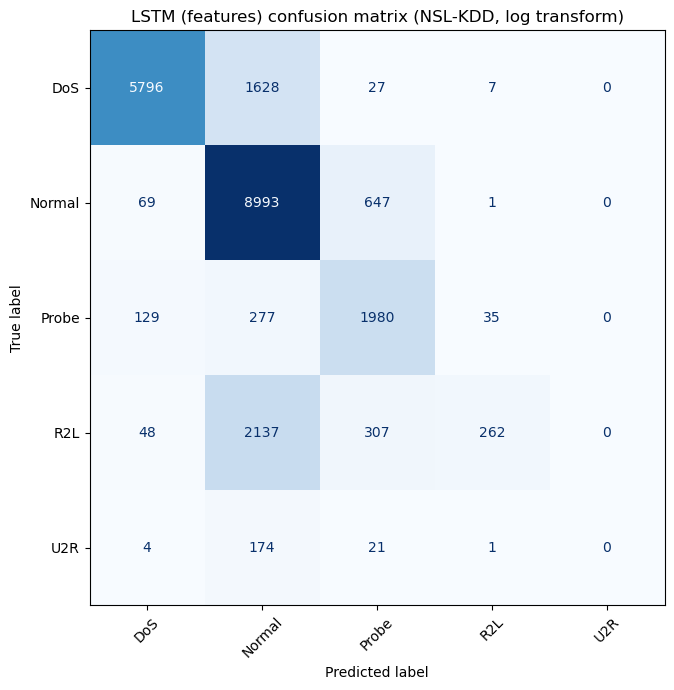

In [14]:
if RUN_LSTM:
    run("lstm_log", "LSTM (features)", "log transform", build_lstm, window=None)
else:
    print("Skipped")

## 6. Comparison

The new runs next to the existing baselines (standard scaling), the optimised runs and the tree models. Files that are not in `results/` are skipped.

Missing: results/NSL-KDD_Decision_Tree.json
Missing: results/NSL-KDD_Random_Forest.json
Missing: results/NSL-KDD_CNN.json
Missing: results/NSL-KDD_CNN_optimised.json
Missing: results/NSL-KDD_LSTM_features.json
Missing: results/NSL-KDD_LSTM_features_optimised.json


,Accuracy,Macro precision,Macro recall,Macro F1,Train time (s)
CNN (log transform),0.7663,0.6519,0.5370,0.5462,39.6619
LSTM (log transform),0.7555,0.6319,0.5233,0.5095,573.0369


,CNN (log transform),LSTM (log transform)
DoS,0.899,0.858
Normal,0.787,0.785
Probe,0.702,0.733
R2L,0.199,0.171
U2R,0.143,0.000


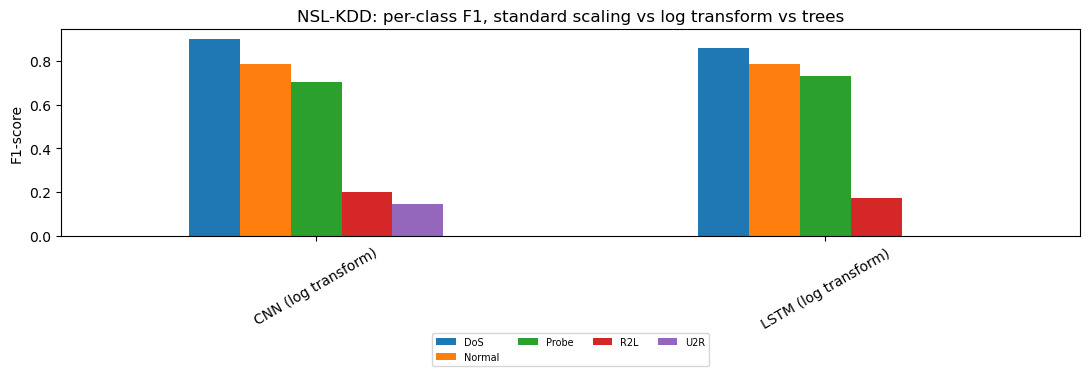

In [15]:
sources = [
    ("Decision Tree", "results/NSL-KDD_Decision_Tree.json", "baseline"),
    ("Random Forest", "results/NSL-KDD_Random_Forest.json", "baseline"),
    ("CNN (standard scaling)", "results/NSL-KDD_CNN.json", "baseline"),
    ("CNN optimised (standard scaling)", "results/NSL-KDD_CNN_optimised.json", "optimised"),
    ("LSTM (standard scaling)", "results/NSL-KDD_LSTM_features.json", "baseline"),
    ("LSTM optimised (standard scaling)", "results/NSL-KDD_LSTM_features_optimised.json", "optimised"),
]
allr = {}
for name, path, key in sources:
    if os.path.exists(path):
        allr[name] = json.load(open(path))[key]
    else:
        print("Missing:", path)
suffix = " + weights" if ALPHA > 0 else ""
labels = {"cnn_log": f"CNN (log transform{suffix})", "lstm_log": f"LSTM (log transform{suffix})"}
for k, name in labels.items():
    if k in results:
        allr[name] = results[k]

summary = pd.DataFrame({n: {"Accuracy": r["accuracy"], "Macro precision": r["macro_precision"],
                            "Macro recall": r["macro_recall"], "Macro F1": r["macro_f1"],
                            "Train time (s)": r.get("train_seconds", float("nan"))}
                        for n, r in allr.items()}).T
display(summary.round(4))

per_class = pd.DataFrame({n: [r["report"][c]["f1-score"] for c in class_names] for n, r in allr.items()},
                         index=class_names)
display(per_class.round(3))
ax = per_class.T.plot.bar(figsize=(11, 4.5), rot=30)
ax.set_ylabel("F1-score")
ax.set_title("NSL-KDD: per-class F1, standard scaling vs log transform vs trees")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.45), ncol=4, fontsize=7)
plt.tight_layout()
plt.show()